# BERT z obcięciem do 512 tokenów (spam w klasie negatywnej)

Wariant `spam_0`: wykrywamy tylko phishing, więc spam należy do klasy negatywnej (etykieta `label_spam_0`).

- **Model:** `bert-base-uncased` dostrajany w całości, z jednym wyjściem na tokenie `[CLS]`. Tekst jest obcinany do 512 tokenów
  (510 tokenów treści), czyli dalsza część długich wiadomości jest pomijana.
- **Tokeny maskowania:** `[URL]`, `[EMAIL_ADDRESS]` i pozostałe są dodane do słownika jako niepodzielne tokeny. Ich początkowy wektor
  to średnia wektorów części, na które dzielił je oryginalny tokenizator.
- **Uczenie:** AdamW (zanik wag 0.01), rozgrzewka przez 10% kroków i liniowy spadek kroku uczenia, batch 16, fp16, przycinanie
  gradientu do normy 1. Batche są wyrównywane do najdłuższej wiadomości w batchu.
- **Dobór hiperparametrów:** krok uczenia z {2e-5, 3e-5, 5e-5} wybierany na jednym foldzie holdout zbioru treningowego (fold 0
  z `cluster_folds`, rozłączny względem klastrów). Pełna 3-krotna walidacja krzyżowa trwałaby około 6 godzin na wariant.
  Kryterium to AUCPR ważone odwrotnością rozmiaru klastra, liczone co pół epoki. Liczba kroków jest dobierana wczesnym
  zatrzymaniem (najwyżej 4 epoki, cierpliwość 2 oceny).
- **Model końcowy:** uczony na całym zbiorze treningowym przez tyle epok, ile wynosiła najlepsza liczba epok na holdoucie.
- **Podział, próg i ocena:** jak w pozostałych eksperymentach (60/30/10 po klastrach, próg przy FPR ważonym 1% na val).

In [ ]:
import gc
import sys
import time
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from sklearn.metrics import average_precision_score

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "notebooks"))
from experiment_utils import (
    ID_SOURCES, INK_SECONDARY, OOD_SOURCES, TARGET_FPR, cluster_folds, cluster_weights, corpus_metrics, load_corpora,
    plot_confusion_matrices, plot_curves, threshold_at_fpr,
)
from bert_utils import DEVICE, encode, load_tokenizer, predict, train_bert

EXPERIMENT = "bert_512_spam_0"
LABEL = "label_spam_0"
RESULTS = ROOT / "results" / EXPERIMENT
TABLES, FIGURES = RESULTS / "tables", RESULTS / "figures"
TABLES.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200, "display.max_columns", 50, "display.max_rows", 100, "display.float_format", "{:.4f}".format)

MAX_LENGTH = 512
BATCH_SIZE = 16
LEARNING_RATES = (2e-5, 3e-5, 5e-5)
MAX_EPOCHS = 4
EVALS_PER_EPOCH = 2
PATIENCE = 2
N_FOLDS, HOLDOUT_FOLD = 3, 0
SEED = 42
REUSE_HOLDOUT = True
LR_COLORS = {2e-5: "#2a78d6", 3e-5: "#eb6834", 5e-5: "#1baf7a"}
print("Urządzenie:", DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "")

/home/ubuntu/phishing-thesis/venv312/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Urządzenie: cuda NVIDIA GeForce RTX 2080


## Dane i podział

In [ ]:
COLUMNS = ["source", "kind", "label_spam_0", "label_spam_1", "cluster", "text"]
in_domain, out_of_domain = load_corpora()
in_domain = in_domain[COLUMNS + ["split", "raw_key"]].rename(columns={"raw_key": "id"})
out_of_domain = out_of_domain[COLUMNS + ["uid"]].rename(columns={"uid": "id"})
train, val, test = (in_domain[in_domain.split == name] for name in ("train", "val", "test"))
assert not set(train.cluster) & set(val.cluster) and not set(train.cluster) & set(test.cluster) and not set(val.cluster) & set(test.cluster)
print({name: len(frame) for name, frame in (("train", train), ("val", val), ("test", test), ("ood", out_of_domain))})

start = time.perf_counter()
tokenizer = load_tokenizer()
id_sequences, in_domain["n_tokens"] = encode(tokenizer, in_domain.text, MAX_LENGTH)
ood_sequences, out_of_domain["n_tokens"] = encode(tokenizer, out_of_domain.text, MAX_LENGTH)
position = pd.Series(np.arange(len(in_domain)), index=in_domain.index)
in_domain, out_of_domain = in_domain.drop(columns="text"), out_of_domain.drop(columns="text")
train, val, test = (in_domain[in_domain.split == name] for name in ("train", "val", "test"))


def sequences(frame):
    return ood_sequences if frame is out_of_domain else [id_sequences[i] for i in position[frame.index]]


truncated = np.mean(in_domain.n_tokens > MAX_LENGTH) * 100
gc.collect()
print(f"Tokenizacja: {time.perf_counter() - start:.0f} s, wiadomości ID obcięte do {MAX_LENGTH} tokenów: {truncated:.1f}%")

{'train': 80679, 'val': 40720, 'test': 13070, 'ood': 6124}


Tokenizacja: 14 s, wiadomości ID obcięte do 512 tokenów: 16.0%


## Wybór kroku uczenia na holdoucie

Część uczącą i holdout wyznacza fold 0 z `cluster_folds`, więc są rozłączne względem klastrów. Dla każdego kroku uczenia model
jest uczony przez najwyżej `MAX_EPOCHS` epok z harmonogramem rozpisanym na ten czas. Co pół epoki liczone jest AUCPR ważone
na holdoucie, a uczenie kończy się po `PATIENCE` ocenach bez poprawy.

In [3]:
fit_index, holdout_index = cluster_folds(train[LABEL], train.cluster, N_FOLDS, SEED)[HOLDOUT_FOLD]
fit_frame, holdout_frame = train.iloc[fit_index], train.iloc[holdout_index]
assert not set(fit_frame.cluster) & set(holdout_frame.cluster)
fit_sequences, holdout_sequences = sequences(fit_frame), sequences(holdout_frame)
holdout_labels, holdout_weights = holdout_frame[LABEL].to_numpy(), cluster_weights(holdout_frame.cluster)
steps_per_epoch = int(np.ceil(len(fit_frame) / BATCH_SIZE))
print(f"Część ucząca: {len(fit_frame)}, holdout: {len(holdout_frame)}, kroków na epokę: {steps_per_epoch}")

grid_rows, history_rows = [], []
grid_start = time.perf_counter()
reuse = REUSE_HOLDOUT and (TABLES / "holdout_results.csv").exists() and (TABLES / "holdout_history.csv").exists()
for learning_rate in () if reuse else LEARNING_RATES:
    start = time.perf_counter()
    print(f"krok uczenia {learning_rate}", flush=True)
    model, history, best_step = train_bert(
        tokenizer, fit_sequences, fit_frame[LABEL], learning_rate, SEED, MAX_EPOCHS * steps_per_epoch,
        batch_size=BATCH_SIZE, holdout=(holdout_sequences, holdout_labels, holdout_weights),
        eval_every=steps_per_epoch // EVALS_PER_EPOCH, patience=PATIENCE, log=lambda text: print(text, flush=True),
    )
    scores = predict(model, tokenizer, holdout_sequences)
    grid_rows.append({
        "learning_rate": learning_rate, "best_step": best_step, "best_epoch": best_step / steps_per_epoch,
        "aucpr_ważone": average_precision_score(holdout_labels, scores, sample_weight=holdout_weights),
        "aucpr": average_precision_score(holdout_labels, scores), "czas_s": time.perf_counter() - start,
    })
    history_rows += [{"learning_rate": learning_rate, "krok": step, "epoka": step / steps_per_epoch, "aucpr_ważone": score} for step, score in history]
    del model
    gc.collect()
    torch.cuda.empty_cache()
grid_seconds = time.perf_counter() - grid_start

if reuse:
    print("Wczytano zapisane wyniki wyboru kroku uczenia.")
    holdout_results, holdout_history = pd.read_csv(TABLES / "holdout_results.csv"), pd.read_csv(TABLES / "holdout_history.csv")
    grid_seconds = holdout_results.czas_s.sum()
else:
    holdout_results = pd.DataFrame(grid_rows).sort_values("aucpr_ważone", ascending=False).reset_index(drop=True)
    holdout_results.to_csv(TABLES / "holdout_results.csv", index=False)
    holdout_history = pd.DataFrame(history_rows)
    holdout_history.to_csv(TABLES / "holdout_history.csv", index=False)
best = holdout_results.iloc[0]
print(f"Czas wyboru kroku uczenia: {grid_seconds / 60:.1f} min")
display(holdout_results)

Część ucząca: 53787, holdout: 26892, kroków na epokę: 3362
Wczytano zapisane wyniki wyboru kroku uczenia.
Czas wyboru kroku uczenia: 83.0 min


,learning_rate,best_step,best_epoch,aucpr_ważone,aucpr,czas_s
0,0.0000,10086,3.0000,0.9558,0.9446,2082.4251
1,0.0000,11767,3.5000,0.9531,0.9432,2085.3647
2,0.0001,1681,0.5000,0.8954,0.8927,811.0729


Przebieg AUCPR ważonego na holdoucie w trakcie uczenia.

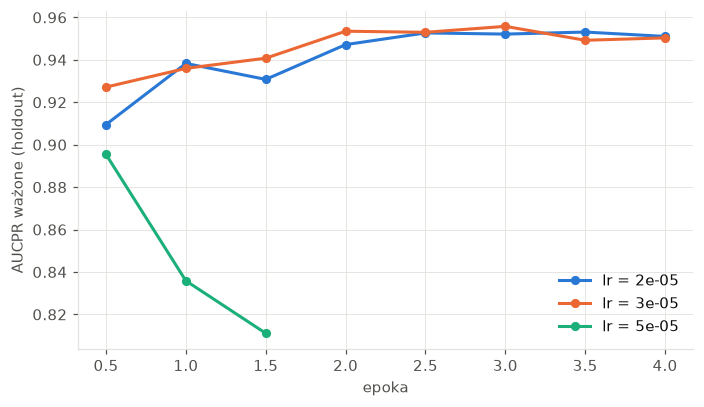

In [4]:
figure, axis = plt.subplots(figsize=(6.5, 3.8))
for learning_rate, color in LR_COLORS.items():
    curve = holdout_history[holdout_history.learning_rate == learning_rate]
    axis.plot(curve.epoka, curve.aucpr_ważone, color=color, linewidth=2, marker="o", markersize=5, label=f"lr = {learning_rate:g}")
axis.set_xlabel("epoka")
axis.set_ylabel("AUCPR ważone (holdout)")
axis.legend(loc="lower right")
figure.tight_layout()
figure.savefig(FIGURES / "holdout_aucpr.pdf")
plt.show()

## Uczenie modelu końcowego

Model z najlepszym krokiem uczenia jest uczony na całym zbiorze treningowym przez najlepszą liczbę epok z holdoutu, z harmonogramem
rozpisanym na tę liczbę kroków.

In [5]:
best_params = {"learning_rate": float(best.learning_rate), "n_epochs": float(best.best_epoch)}
final_steps = max(1, int(round(best.best_epoch * np.ceil(len(train) / BATCH_SIZE))))
start = time.perf_counter()
model, _, _ = train_bert(tokenizer, sequences(train), train[LABEL], best_params["learning_rate"], SEED, final_steps, batch_size=BATCH_SIZE)
training_seconds = time.perf_counter() - start
print(best_params, f"kroków: {final_steps}, czas uczenia: {training_seconds / 60:.1f} min")


def score(frame):
    return predict(model, tokenizer, sequences(frame))


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2354.47it/s]

{'learning_rate': 3e-05, 'n_epochs': 3.0} kroków: 15129, czas uczenia: 31.7 min


## Dobór progu na zbiorze walidacyjnym

In [6]:
threshold_result = threshold_at_fpr(val[LABEL], score(val), val.cluster)
threshold = threshold_result["próg"]
threshold_table = pd.DataFrame([{
    "docelowy_fpr": TARGET_FPR, **threshold_result, **best_params, "kroki": final_steps,
    "aucpr_ważone_holdout": best["aucpr_ważone"], "czas_wyboru_lr_s": grid_seconds, "czas_uczenia_s": training_seconds,
}])
threshold_table.to_csv(TABLES / "threshold.csv", index=False)
display(threshold_table)

,docelowy_fpr,próg,fpr_ważony_val,fpr_val,recall_val,learning_rate,n_epochs,kroki,aucpr_ważone_holdout,czas_wyboru_lr_s,czas_uczenia_s
0,0.0100,0.5658,0.0100,0.0183,0.9439,0.0000,3.0000,15129,0.9558,4978.8627,1904.3380


## Metryki dla ID i OOD

In [7]:
test_scores, ood_scores = score(test), score(out_of_domain)
corpus_sets = {"ID": (test[LABEL], test_scores), "OOD": (out_of_domain[LABEL], ood_scores)}
metrics = corpus_metrics(corpus_sets, threshold)
metrics.to_csv(TABLES / "metrics.csv", index_label="korpus")
display(metrics)

,n,positives,accuracy,recall,f1,precision,roc_auc,aucpr,fpr
ID,13070.0000,1253.0000,0.9794,0.9322,0.8967,0.8639,0.9912,0.9411,0.0156
OOD,6124.0000,4987.0000,0.4943,0.4756,0.6050,0.8311,0.5597,0.8522,0.4239


## Metryki według źródła

Puste wartości oznaczają metrykę, której nie da się policzyć dla jednej klasy, np. FPR dla Nazario, które ma tylko phishing.

In [8]:
source_sets = {
    name: (test.loc[test.source == name, LABEL], test_scores[(test.source == name).to_numpy()]) for name in ID_SOURCES
} | {
    name: (out_of_domain.loc[out_of_domain.source == name, LABEL], ood_scores[(out_of_domain.source == name).to_numpy()])
    for name in OOD_SOURCES
}
metrics_by_source = corpus_metrics(source_sets, threshold)
metrics_by_source.to_csv(TABLES / "metrics_by_source.csv", index_label="source")
display(metrics_by_source)

,n,positives,accuracy,recall,f1,precision,roc_auc,aucpr,fpr
nazario,918.0000,918.0000,0.9597,0.9597,0.9794,1.0000,NaN,NaN,NaN
nigerian,335.0000,335.0000,0.8567,0.8567,0.9228,1.0000,NaN,NaN,NaN
trec05,5386.0000,0.0000,0.9772,NaN,0.0000,0.0000,NaN,NaN,0.0228
trec06,1582.0000,0.0000,0.9829,NaN,0.0000,0.0000,NaN,NaN,0.0171
trec07,4849.0000,0.0000,0.9930,NaN,0.0000,0.0000,NaN,NaN,0.0070
ferb,5601.0000,4707.0000,0.4724,0.4602,0.5945,0.8395,0.5222,0.8689,0.4631
kd10000,60.0000,55.0000,0.7333,0.7091,0.8298,1.0000,1.0000,1.0000,0.0000
nebulon,145.0000,69.0000,0.7310,0.6232,0.6880,0.7679,0.7607,0.7423,0.1711
zeroday,318.0000,156.0000,0.7264,0.7949,0.7403,0.6927,0.8186,0.8209,0.3395


## Macierze pomyłek i krzywe

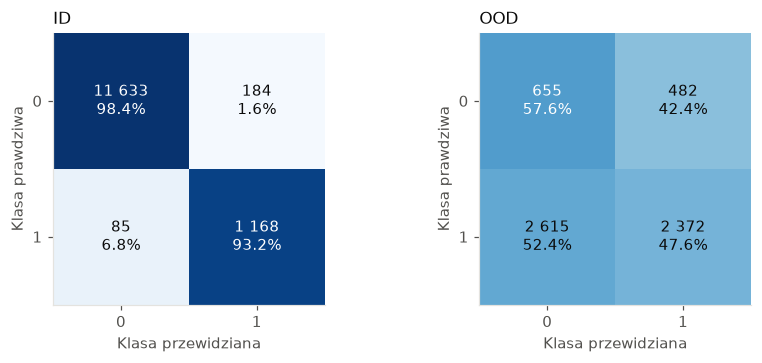

,przewidziane 0,przewidziane 1
prawdziwe 0,11633,184
prawdziwe 1,85,1168


,przewidziane 0,przewidziane 1
prawdziwe 0,655,482
prawdziwe 1,2615,2372


In [9]:
matrices = plot_confusion_matrices(corpus_sets, threshold, FIGURES / "confusion_matrices.pdf")
for name, matrix in matrices.items():
    matrix.to_csv(TABLES / f"confusion_matrix_{name.lower()}.csv")
    display(matrix)

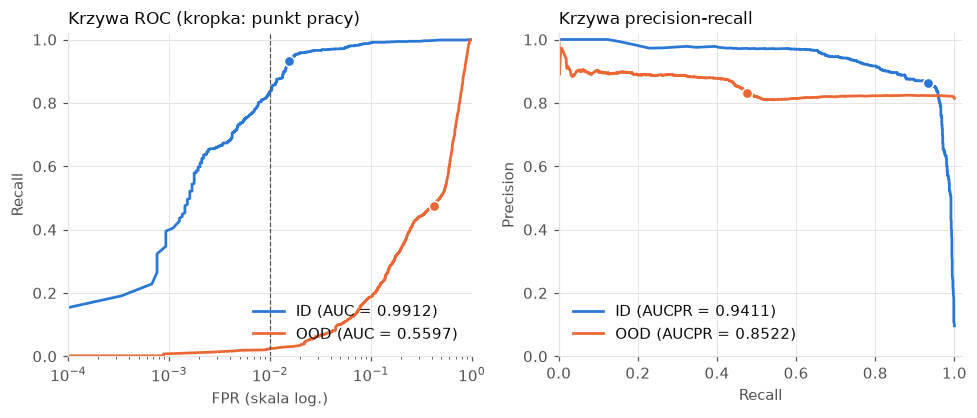

In [10]:
plot_curves(corpus_sets, threshold, FIGURES / "roc_pr_curves.pdf")

## Predykcje na teście

Wynik modelu dla każdej wiadomości testowej ID i OOD, z liczbą tokenów przed obcięciem. Służą do analizy błędów
(`bert_512_error_analysis.ipynb`). `id` to `raw_key` dla ID i `uid` dla OOD.

In [11]:
predictions = pd.concat([
    frame[["id", "source", "kind", "cluster", "n_tokens"]].assign(korpus=name, label=frame[LABEL].to_numpy(), score=scores)
    for name, frame, scores in (("ID", test, test_scores), ("OOD", out_of_domain, ood_scores))
], ignore_index=True)
predictions["pred"] = (predictions.score >= threshold).astype(int)
predictions["truncated"] = predictions.n_tokens > MAX_LENGTH
predictions.to_csv(TABLES / "predictions.csv", index=False)
print(predictions.groupby("korpus").truncated.mean())

korpus
ID    0.2015
OOD   0.0002
Name: truncated, dtype: float64
